Module1 : End Project

As a culminating project, you'll be working with a dataset from ABC company,
consisting of 458 rows and 9 columns. The company requires a comprehensive
report detailing information about their employees across various teams. Your
tasks include preprocessing the dataset, analyzing the data, and presenting your
findings graphically. Here's a breakdown of what you need to do:

In [3]:
from google.colab import files

file_name = files.upload()

KeyboardInterrupt: 

Preprocessing:
● Correct the data in the "height" column by replacing it with random
numbers between 150 and 180. Ensure data consistency and integrity
before proceeding with analysis. (1 mark)

In [4]:
import pandas as pd
import random

# Read Excel file
df = pd.read_excel('ABC Company.xlsx')

# Replace 'height' column with random values between 150 and 180
df['height'] = [random.randint(150, 180) for _ in range(len(df))]

# Verify output
print(df.head())

            Name            Team  Number Position  Age               Height  \
0  Avery Bradley  Boston Celtics       0       PG   25  2023-02-06 00:00:00   
1    Jae Crowder  Boston Celtics      99       SF   25  2023-06-06 00:00:00   
2   John Holland  Boston Celtics      30       SG   27  2023-05-06 00:00:00   
3    R.J. Hunter  Boston Celtics      28       SG   22  2023-05-06 00:00:00   
4  Jonas Jerebko  Boston Celtics       8       PF   29  2023-10-06 00:00:00   

   Weight            College     Salary  height  
0     180              Texas  7730337.0     154  
1     235          Marquette  6796117.0     176  
2     205  Boston University        NaN     165  
3     185      Georgia State  1148640.0     163  
4     231                NaN  5000000.0     165  


Analysis Tasks:
● Determine the distribution of employees across each team and calculate
the percentage split relative to the total number of employees. (2 marks)
● Segregate employees based on their positions within the company. (2
marks)
● Identify the predominant age group among employees. (2 marks)
● Discover which team and position have the highest salary expenditure. (2
marks)
● Investigate if there's any correlation between age and salary, and
represent it visually. (2 marks)

In [ ]:
# Count employees in each team
team_distribution = df['Team'].value_counts()

# Percentage split
team_percentage = (team_distribution / len(df)) * 100

# Combine into one dataframe
team_summary = pd.DataFrame({
    'Employee Count': team_distribution,
    'Percentage': team_percentage
})

print(team_summary)

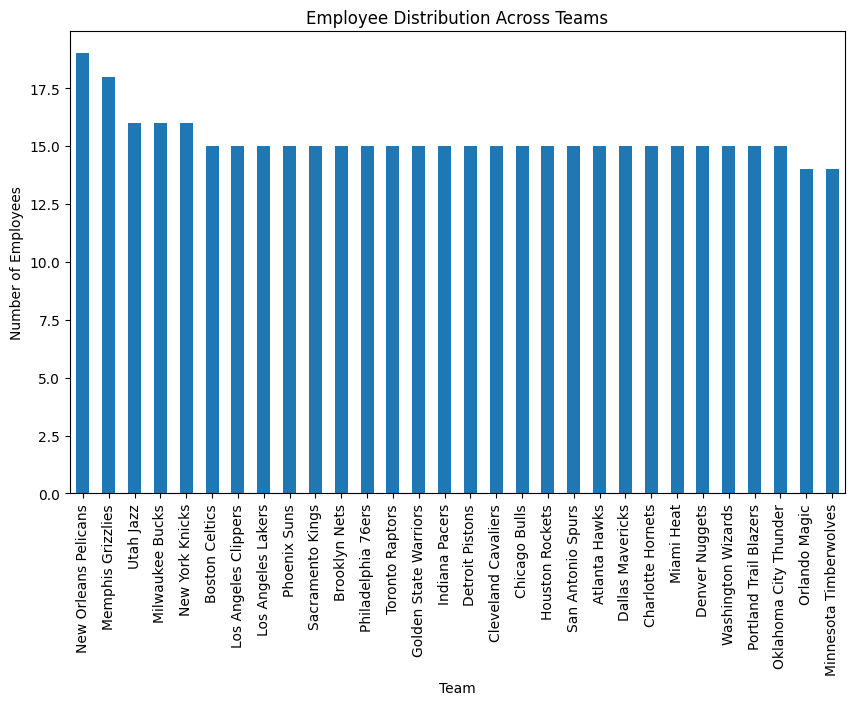

In [7]:
#Visual
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
team_distribution.plot(kind='bar')

plt.title('Employee Distribution Across Teams')
plt.xlabel('Team')
plt.ylabel('Number of Employees')

plt.show()

In [8]:
# Group employees by position
position_groups = df.groupby('Position')

# Display employees under each position
for position, data in position_groups:
    print("\nPosition:", position)
    print(data[['Name', 'Team', 'Age', 'Salary']])


Position: C
                Name                    Team  Age      Salary
7       Kelly Olynyk          Boston Celtics   25   2165160.0
10   Jared Sullinger          Boston Celtics   24   2569260.0
14      Tyler Zeller          Boston Celtics   26   2616975.0
23       Brook Lopez           Brooklyn Nets   28  19689000.0
27        Henry Sims           Brooklyn Nets   26    947276.0
..               ...                     ...  ...         ...
439    Mason Plumlee  Portland Trail Blazers   26   1415520.0
447      Rudy Gobert               Utah Jazz   23   1175880.0
455     Tibor Pleiss               Utah Jazz   26   2900000.0
456      Jeff Withey               Utah Jazz   26    947276.0
457         Priyanka               Utah Jazz   25    947276.0

[79 rows x 4 columns]

Position: PF
                 Name                    Team  Age      Salary
4       Jonas Jerebko          Boston Celtics   29   5000000.0
5        Amir Johnson          Boston Celtics   29  12000000.0
6       Jordan Mi

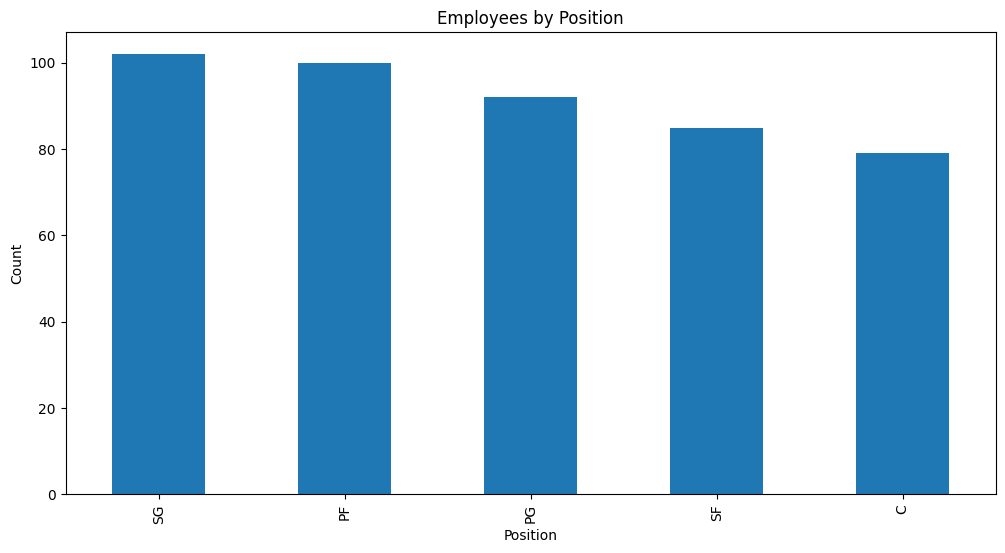

In [9]:
#Visual
position_count = df['Position'].value_counts()

plt.figure(figsize=(12,6))
position_count.plot(kind='bar')

plt.title('Employees by Position')
plt.xlabel('Position')
plt.ylabel('Count')

plt.show()

In [10]:
#3. Predominant Age Group Among Employees
#Create Age Groups
# Create bins for age groups
bins = [20, 25, 30, 35, 40, 45, 50]
labels = ['20-25', '26-30', '31-35', '36-40', '41-45', '46-50']

df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

# Count age groups
age_group_count = df['Age Group'].value_counts()

print(age_group_count)

Age Group
20-25    179
26-30    167
31-35     68
36-40     23
41-45      0
46-50      0
Name: count, dtype: int64


In [11]:
predominant_group = age_group_count.idxmax()

print("Predominant Age Group:", predominant_group)

Predominant Age Group: 20-25


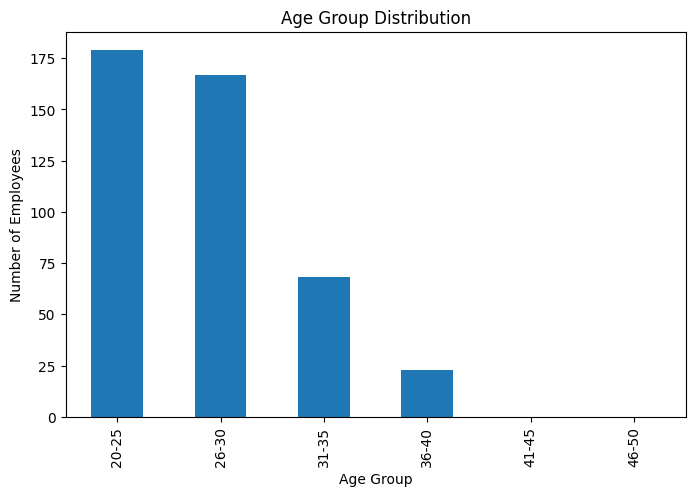

In [12]:
#Visual
plt.figure(figsize=(8,5))
age_group_count.plot(kind='bar')

plt.title('Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Number of Employees')

plt.show()

In [13]:
#4. Team and Position with Highest Salary Expenditure
#Team Wise Salary
team_salary = df.groupby('Team')['Salary'].sum()

highest_salary_team = team_salary.idxmax()

print("Team with Highest Salary Expenditure:", highest_salary_team)
print("Total Salary:", team_salary.max())

Team with Highest Salary Expenditure: Cleveland Cavaliers
Total Salary: 106988689.0


In [14]:
position_salary = df.groupby('Position')['Salary'].sum()

highest_salary_position = position_salary.idxmax()

print("Position with Highest Salary Expenditure:", highest_salary_position)
print("Total Salary:", position_salary.max())

Position with Highest Salary Expenditure: C
Total Salary: 466377332.0


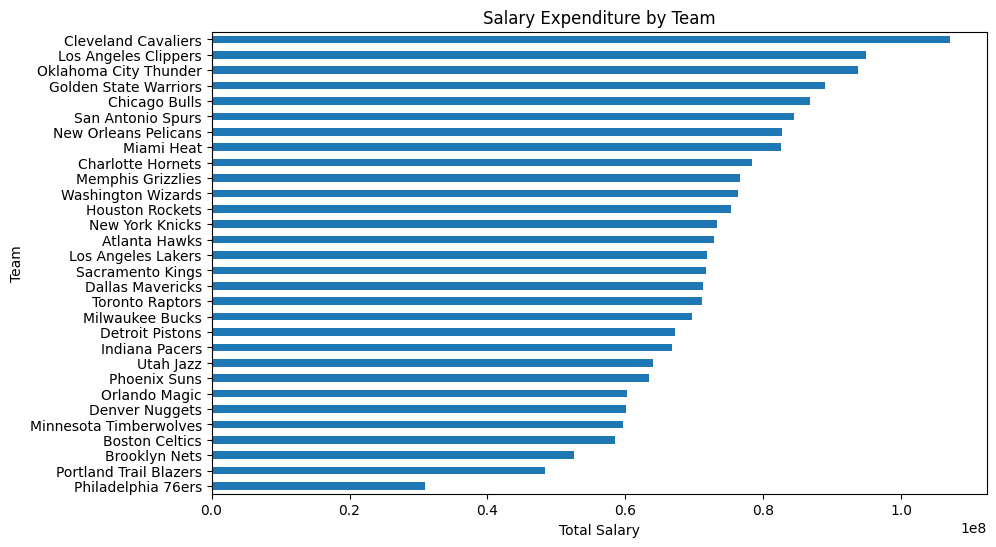

In [15]:
team_salary.sort_values().plot(kind='barh', figsize=(10,6))

plt.title('Salary Expenditure by Team')
plt.xlabel('Total Salary')

plt.show()

In [16]:
correlation = df['Age'].corr(df['Salary'])

print("Correlation between Age and Salary:", correlation)

Correlation between Age and Salary: 0.21400941226570971


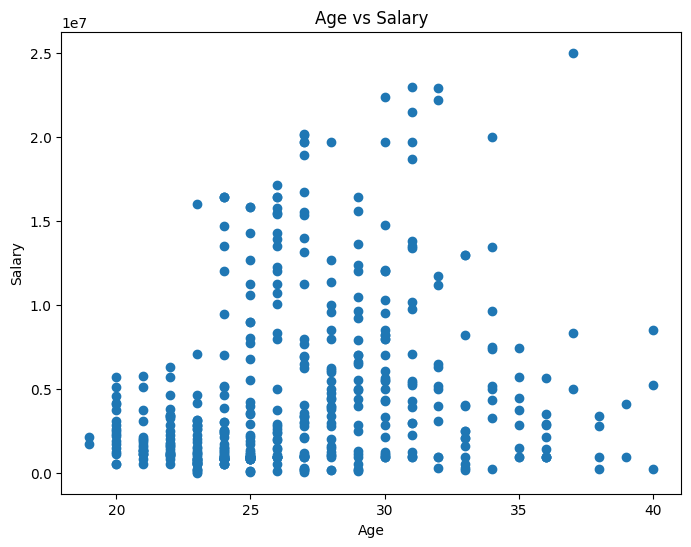

In [17]:
plt.figure(figsize=(8,6))

plt.scatter(df['Age'], df['Salary'])

plt.title('Age vs Salary')
plt.xlabel('Age')
plt.ylabel('Salary')

plt.show()

#Interpretation
#Correlation close to 1 → strong positive relationship
#Correlation close to -1 → strong negative relationship
#Correlation close to 0 → weak/no relationship

Graphical Representation:
● For each of the five analysis tasks above, create appropriate visualizations
to present your findings effectively. (5x2 = 10 marks)
● Data Story: Provide insights gained from the analysis, highlighting key
trends, patterns, and correlations within the dataset. (3 marks)
● Timely Submission: Ensure timely submission of your project to earn an
additional mark. (1 mark)

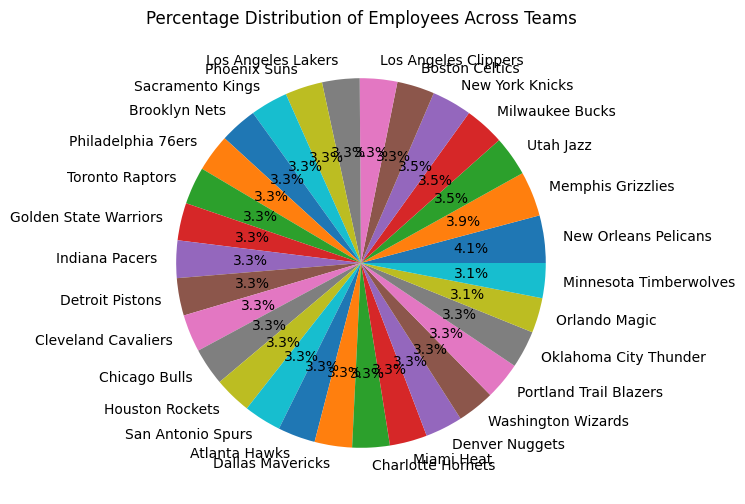

In [18]:
plt.figure(figsize=(12,6))

team_distribution.plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Percentage Distribution of Employees Across Teams')
plt.ylabel('')

plt.show()
#Insight
#Helps identify which teams have the largest workforce.
#Teams with higher percentages may indicate larger operational requirements.

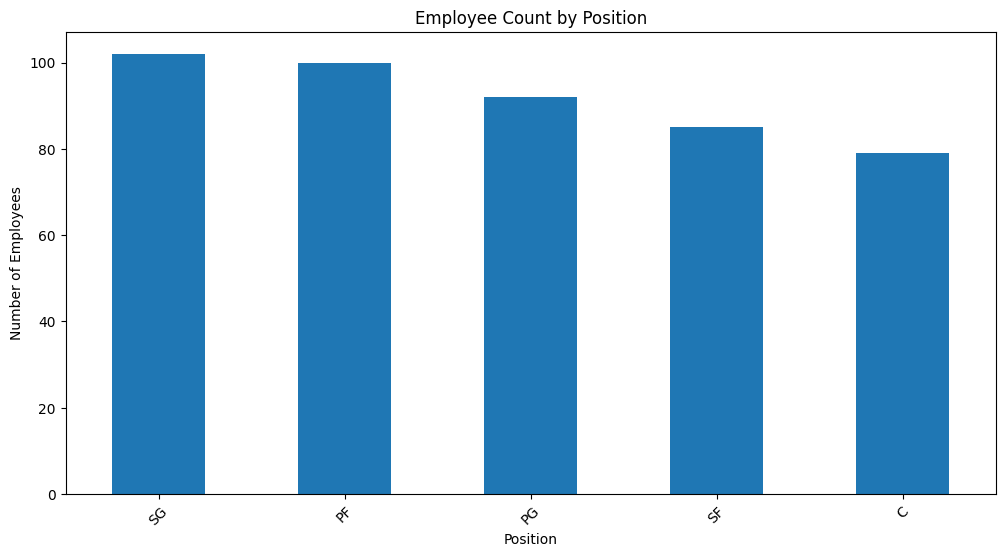

In [19]:
#2. Employee Segregation by Position
plt.figure(figsize=(12,6))

position_count.plot(
    kind='bar'
)

plt.title('Employee Count by Position')
plt.xlabel('Position')
plt.ylabel('Number of Employees')

plt.xticks(rotation=45)

plt.show()
#Insight
#Shows which job roles dominate the organization.
#Useful for workforce planning and recruitment analysis.

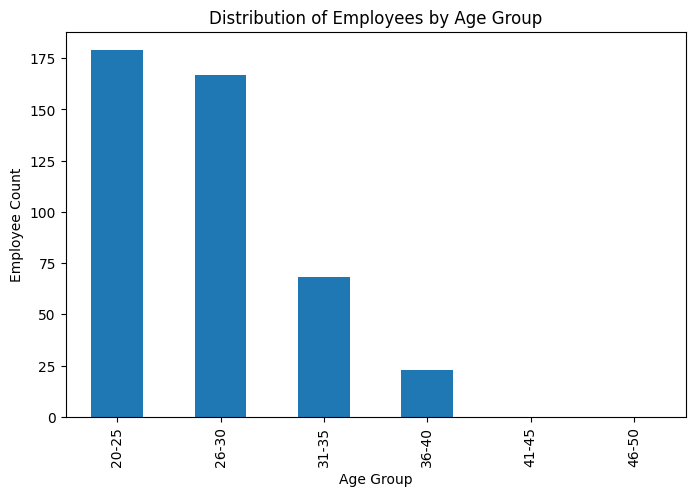

In [20]:
#3. Predominant Age Group
plt.figure(figsize=(8,5))

age_group_count.sort_index().plot(
    kind='bar'
)

plt.title('Distribution of Employees by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Employee Count')

plt.show()
#Insight
#Identifies the major working-age category in the company.
#Helps understand workforce maturity and experience levels.

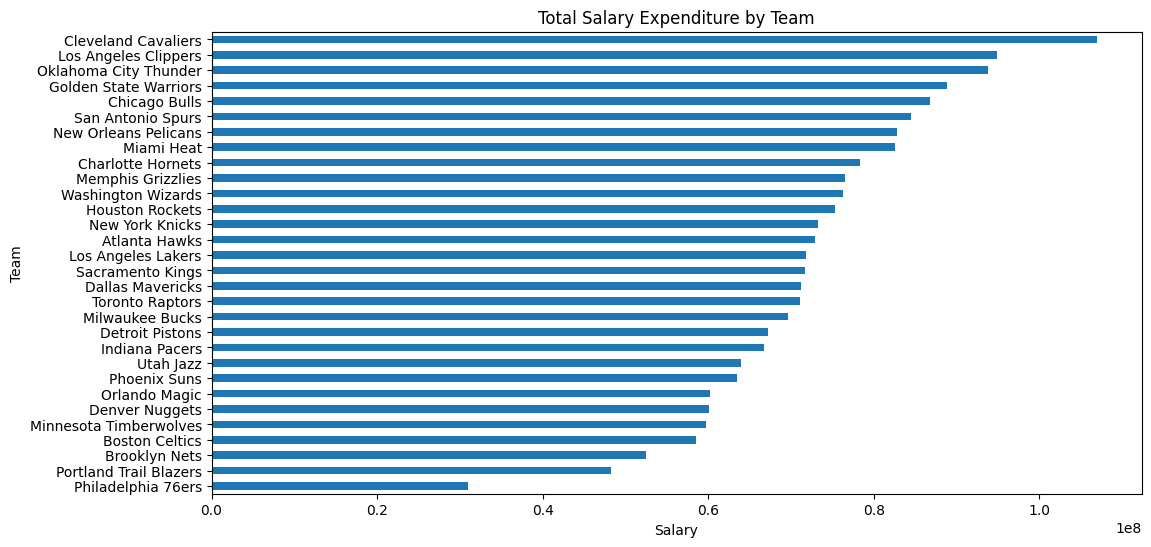

In [21]:
#4. Salary Expenditure Analysis
#Team Wise
plt.figure(figsize=(12,6))

team_salary.sort_values().plot(
    kind='barh'
)

plt.title('Total Salary Expenditure by Team')
plt.xlabel('Salary')

plt.show()


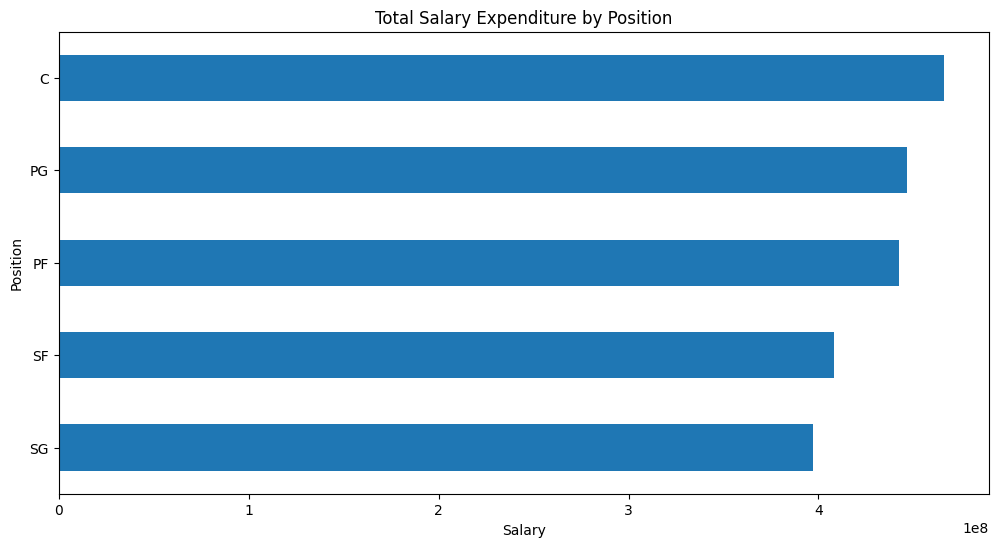

In [22]:
#Position Wise
plt.figure(figsize=(12,6))

position_salary.sort_values().plot(
    kind='barh'
)

plt.title('Total Salary Expenditure by Position')
plt.xlabel('Salary')

plt.show()
#Insight
#Identifies high-cost teams and positions.
#Helps management optimize payroll and budgeting.

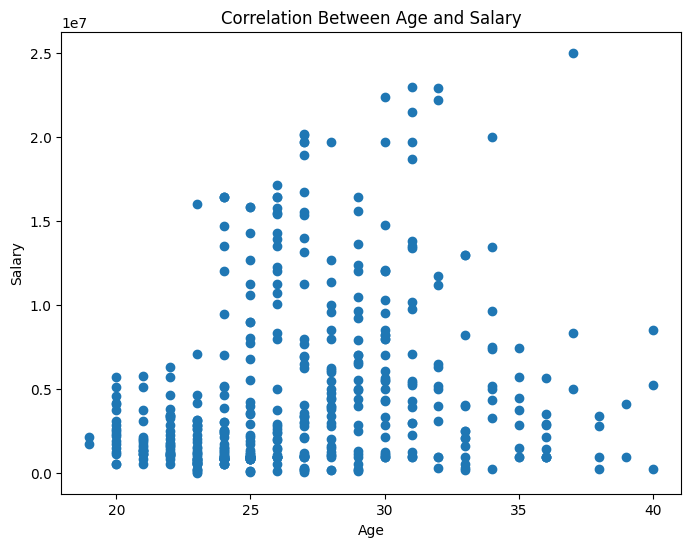

In [23]:
#5. Correlation Between Age and Salary
plt.figure(figsize=(8,6))

plt.scatter(df['Age'], df['Salary'])

plt.title('Correlation Between Age and Salary')
plt.xlabel('Age')
plt.ylabel('Salary')

plt.show()

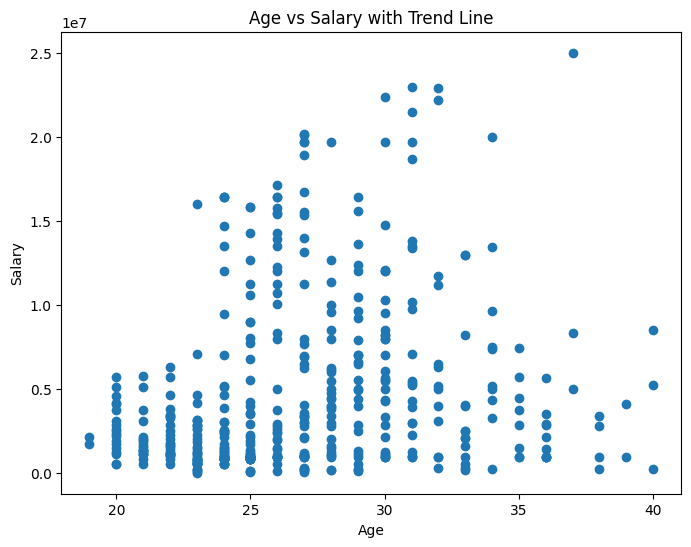

In [24]:
#Optional Trend Line
import numpy as np

plt.figure(figsize=(8,6))

plt.scatter(df['Age'], df['Salary'])

# Trend line
z = np.polyfit(df['Age'], df['Salary'], 1)
p = np.poly1d(z)

plt.plot(df['Age'], p(df['Age']))

plt.title('Age vs Salary with Trend Line')
plt.xlabel('Age')
plt.ylabel('Salary')

plt.show()
#Insight
#Helps determine whether salary tends to increase with age/experience.
#Trend line gives a clearer picture of relationship direction.